<a href="https://colab.research.google.com/github/amanpoonia/SBeta_preparation/blob/main/Risk/t-VaR_t_student_shocks.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
'''
Empirically returns are known to have fat tails.
Normal distribution doesn't have fat tails. Introducing t-student distribution.

N(mu, sigma)
t(loc, scale, df)

Steps:
Fit a t-student distribution, estimate the parameters
Parameters are estimated using MLE.


'''
# variance = (scale^2)*(df/(df-2))

5. **Why to simulate day by day**

With normal shocks, the sum of 5 daily shocks is still normal, so one draw scaled by √5 was exact. The sum of 5 t-distributed shocks is not t-distributed. It has no simple closed form, so you draw 5 daily shocks for each scenario and add them up.

There is a consequence. If daily returns are **i.i.d.**, summing them pushes the result toward normal (central limit theorem). Kurtosis falls roughly as K/h over h days, so a 5-day i.i.d. t sum already has much thinner tails than a single t-distributed day.

Real 5-day returns, however, stay fat-tailed, because bad days cluster together. The i.i.d. t model can’t produce that clustering. GARCH can.

6. **Fitting ν**

There are two ways to estimate ν:

Maximum likelihood: t.fit(p_ret) returns (nu, loc, scale). This is the standard approach.
Moment matching: ν = 4 + 6/K from sample kurtosis. It’s quick, but noisy, because K is dominated by a handful of extreme days.

Model vs reality:

a modelling limitation (the i.i.d. assumption). You fix it later with GARCH, which builds clustering into the model.

In [31]:
import numpy as np
import pandas as pd
import yfinance as yf
import matplotlib.pyplot as plt
import datetime as dt
from scipy.stats import t
from scipy.stats import skew, kurtosis

# Download and close prices/returns data for a time period
years = 15
start_date = dt.datetime.today() - dt.timedelta(days=365*years)
end_date = dt.datetime.today()
#start_date = '2008-04-28'
#end_date = '2023-04-25'

tickers = ['SPY', 'BND', 'GLD', 'QQQ', 'VTI']
adj_close = pd.DataFrame()

for ticker in tickers:
  # Use multi_level_index=False to prevent MultiIndex columns and retrieve the adjusted 'Close'
  data = yf.download(ticker, start=start_date, end=end_date, multi_level_index=False)
  adj_close[ticker] = data['Close']

# Log Returns
log_ret = np.log(adj_close / adj_close.shift(1))
log_ret.dropna(inplace=True)

# Portfolio
# Weighing equally weighted
weights = np.array([1/len(tickers)]*len(tickers))

# Portfolio historical returns
p_ret = (log_ret * weights).sum(axis=1)

/tmp/ipykernel_2058/2231440526.py:21: FutureWarning: YF.download() has changed argument auto_adjust default to True
  data = yf.download(ticker, start=start_date, end=end_date, multi_level_index=False)
[*********************100%***********************]  1 of 1 completed
/tmp/ipykernel_2058/2231440526.py:21: FutureWarning: YF.download() has changed argument auto_adjust default to True
  data = yf.download(ticker, start=start_date, end=end_date, multi_level_index=False)
[*********************100%***********************]  1 of 1 completed
/tmp/ipykernel_2058/2231440526.py:21: FutureWarning: YF.download() has changed argument auto_adjust default to True
  data = yf.download(ticker, start=start_date, end=end_date, multi_level_index=False)
[*********************100%***********************]  1 of 1 completed
/tmp/ipykernel_2058/2231440526.py:21: FutureWarning: YF.download() has changed argument auto_adjust default to True
  data = yf.download(ticker, start=start_date, end=end_date, multi_leve

Skew: -0.49
Kurtosis: 13.18
Raw Kurtosis: 16.18

nu:3.16
loc:0.00
scale:0.00


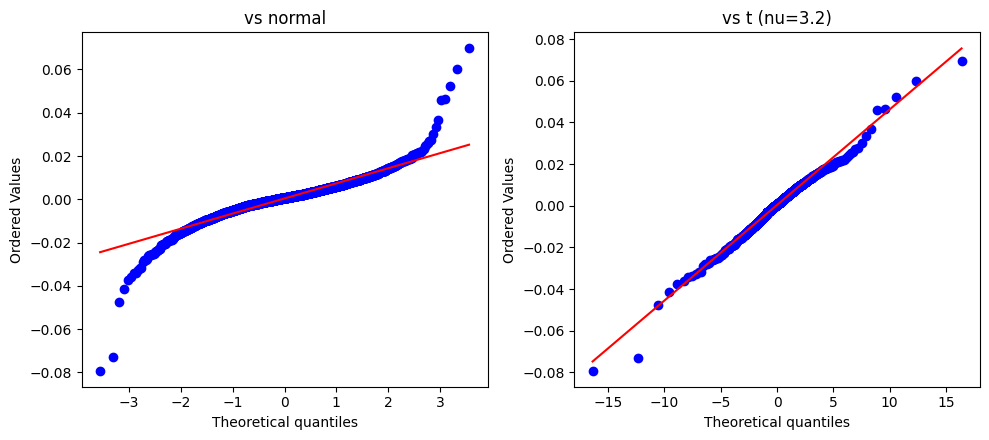

In [56]:
# Before fitting a t-distribution to the returns
# Checking skewness and kurtosis
import scipy.stats as stats

skw = stats.skew(p_ret)
kurt = stats.kurtosis(p_ret) #excess kurtosis
raw_kurt = stats.kurtosis(p_ret, fisher=False)#raw kurtosis
print(f'Skew: {skw:.2f}\nKurtosis: {kurt:.2f}\nRaw Kurtosis: {raw_kurt:.2f}')

from scipy.stats import probplot
'''
fig, ax = plt.subplots(figsize=(5, 5))
probplot(p_ret, dist="norm", plot=ax)
ax.set_title("QQ-plot: portfolio returns vs normal")
plt.show()
'''
# plot shows fat tails(too down in left, too up in right), and some
# skewness(longer center left?)
# Model fit
x = p_ret.values
nu, loc, scale = t.fit(x)
print(f'\nnu:{nu:.2f}\nloc:{loc:.2f}\nscale:{scale:.2f}')

fig, ax = plt.subplots(1, 2, figsize=(10, 4.5))
probplot(p_ret, dist="norm", plot=ax[0])
ax[0].set_title("vs normal")
probplot(p_ret, dist=t, sparams=(nu,), plot=ax[1])
ax[1].set_title(f"vs t (nu={nu:.1f})")
plt.tight_layout(); plt.show()


In [103]:
def simulate(nu, loc, scale, n_sim, days):
  rng = np.random.default_rng(42)
  sim = t.rvs(nu, loc, scale, size=(n_sim, days), random_state=rng)
  R = sim.sum(axis=1)
  return R

def pnl(Portfolio_value, nu, loc, scale, n_sim, days):
  days_R = simulate(nu, loc, scale, n_sim, days)
  pl = Portfolio_value * (np.exp(days_R) - 1)
  return pl

n_sim = 100000
days = 5
Portfolio_value = 1000000
confidence_level = 0.99

PL = pnl(Portfolio_value, nu, loc, scale, n_sim, days)

VaR = -np.percentile(PL, 100*(1-confidence_level))
cVaR = -np.mean(PL[PL <= -VaR])
print(f'VaR:  ${VaR:.2f}')
print(f'cVaR: ${cVaR:.2f}')

VaR:  $38309.59
cVaR: $54579.25
